# Laboratorio 9 - Deep Learning

- Juan Solís - 23720
- Victor Pérez - 23731
- Diego Flores - 23714
- Nils Muralles - 23727
- Isabella Recinos - 23003

## Task 3

### Task 3.1

Se implementa una U-Net pequeña condicionada por el instante y la clase. La clase 10 representa la condición nula.

In [1]:
import math
import torch
import torch.nn as nn

SEED = 42
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError("dim debe ser par")
        frequencies = torch.exp(
            torch.arange(0, dim, 2, dtype=torch.float32)
            * (-math.log(10000.0) / dim)
        )
        self.dim = dim
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float().unsqueeze(1) * self.frequencies.unsqueeze(0)
        embedding = torch.empty(t.size(0), self.dim, device=t.device)
        embedding[:, 0::2] = torch.sin(angles)
        embedding[:, 1::2] = torch.cos(angles)
        return embedding


class ConditionedBlock(nn.Module):
    def __init__(self, in_channels, out_channels, condition_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.condition_projection = nn.Linear(condition_dim, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.activation = nn.SiLU()

    def forward(self, x, condition):
        h = self.activation(self.norm1(self.conv1(x)))
        h = h + self.condition_projection(condition)[:, :, None, None]
        h = self.activation(self.norm2(self.conv2(h)))
        return h


class SmallConditionalUNet(nn.Module):
    def __init__(self, condition_dim=64):
        super().__init__()
        self.time_embedding = SinusoidalEmbedding(condition_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(condition_dim, condition_dim),
            nn.SiLU(),
            nn.Linear(condition_dim, condition_dim),
        )
        self.class_embedding = nn.Embedding(11, condition_dim)

        self.encoder_28 = ConditionedBlock(1, 32, condition_dim)
        self.downsample = nn.Conv2d(32, 64, 4, stride=2, padding=1)
        self.encoder_14 = ConditionedBlock(64, 64, condition_dim)
        self.bottleneck = ConditionedBlock(64, 64, condition_dim)

        self.upsample = nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1)
        self.decoder_28 = ConditionedBlock(64, 32, condition_dim)
        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x, t, c):
        time_condition = self.time_mlp(self.time_embedding(t))
        class_condition = self.class_embedding(c)
        condition = time_condition + class_condition

        skip = self.encoder_28(x, condition)
        h = self.downsample(skip)
        h = self.encoder_14(h, condition)
        h = self.bottleneck(h, condition)
        h = self.upsample(h)
        h = torch.cat([h, skip], dim=1)
        h = self.decoder_28(h, condition)
        return self.output(h)


model = SmallConditionalUNet().to(device)
x = torch.randn(4, 1, 28, 28, device=device)
t = torch.tensor([1, 250, 500, 1000], device=device)
c = torch.tensor([0, 3, 10, 7], device=device)

model.eval()
with torch.no_grad():
    predicted_noise = model(x, t, c)

parameter_count = sum(p.numel() for p in model.parameters())
assert predicted_noise.shape == x.shape
assert torch.isfinite(predicted_noise).all()
assert parameter_count == 272929

print("Forma de entrada:", tuple(x.shape))
print("Forma de salida:", tuple(predicted_noise.shape))
print("Parametros totales:", parameter_count)
print("Semilla:", SEED, "| device:", device)

Forma de entrada: (4, 1, 28, 28)
Forma de salida: (4, 1, 28, 28)
Parametros totales: 272929
Semilla: 42 | device: cuda


### Task 3.2

Se entrena el modelo para predecir el ruido y se evalúa la pérdida en 10 intervalos de tiempo.

In [2]:
import matplotlib.pyplot as plt
from torchvision import datasets

epochs = 30
batch_size = 128
lr = 2e-4
p_uncond = 0.1
T = 1000
beta_start = 1e-4
beta_end = 0.02

data = datasets.FashionMNIST("data", train=True, download=True)
X = (data.data.float() / 255.0 * 2 - 1).unsqueeze(1)
Y = data.targets
x_train, y_train = X[:-5000].to(device), Y[:-5000].to(device)
x_val, y_val = X[-5000:].to(device), Y[-5000:].to(device)

betas = torch.linspace(beta_start, beta_end, T, device=device)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, eps):
    ab = alpha_bar[t - 1].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

print("Entrenamiento:", tuple(x_train.shape))
print("Validacion:", tuple(x_val.shape))

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.2MB/s]


Entrenamiento: (55000, 1, 28, 28)
Validacion: (5000, 1, 28, 28)


Epoca 01/30: perdida = 0.13523
Epoca 02/30: perdida = 0.06588
Epoca 03/30: perdida = 0.05756
Epoca 04/30: perdida = 0.05453
Epoca 05/30: perdida = 0.05186
Epoca 06/30: perdida = 0.05053
Epoca 07/30: perdida = 0.05005
Epoca 08/30: perdida = 0.04876
Epoca 09/30: perdida = 0.04730
Epoca 10/30: perdida = 0.04651
Epoca 11/30: perdida = 0.04627
Epoca 12/30: perdida = 0.04618
Epoca 13/30: perdida = 0.04545
Epoca 14/30: perdida = 0.04460
Epoca 15/30: perdida = 0.04444
Epoca 16/30: perdida = 0.04454
Epoca 17/30: perdida = 0.04366
Epoca 18/30: perdida = 0.04383
Epoca 19/30: perdida = 0.04305
Epoca 20/30: perdida = 0.04257
Epoca 21/30: perdida = 0.04298
Epoca 22/30: perdida = 0.04330
Epoca 23/30: perdida = 0.04224
Epoca 24/30: perdida = 0.04291
Epoca 25/30: perdida = 0.04235
Epoca 26/30: perdida = 0.04283
Epoca 27/30: perdida = 0.04193
Epoca 28/30: perdida = 0.04233
Epoca 29/30: perdida = 0.04153
Epoca 30/30: perdida = 0.04175


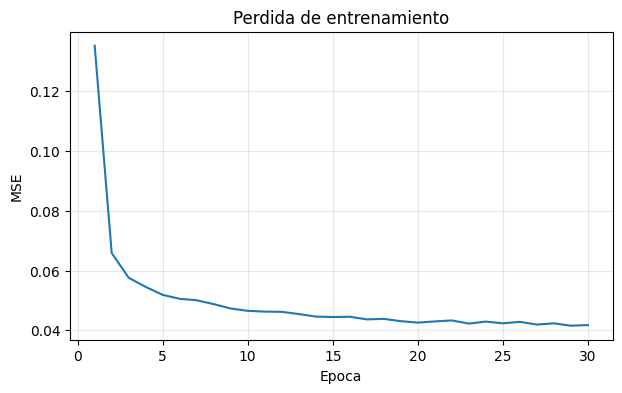

In [3]:
from pathlib import Path

torch.manual_seed(SEED)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
diffusion_checkpoint = Path("data/task3_diffusion_checkpoint.pt")
diffusion_checkpoint.parent.mkdir(parents=True, exist_ok=True)

if diffusion_checkpoint.exists():
    saved = torch.load(diffusion_checkpoint, map_location=device)
    model.load_state_dict(saved["model"])
    optimizer.load_state_dict(saved["optimizer"])
    train_losses = saved["train_losses"]
    start_epoch = len(train_losses)
    print(f"Checkpoint cargado: {start_epoch} epocas")
else:
    train_losses = []
    start_epoch = 0

for epoch in range(start_epoch, epochs):
    model.train()
    permutation = torch.randperm(len(x_train), device=device)
    total_loss = 0.0

    for i in range(0, len(x_train), batch_size):
        indices = permutation[i:i + batch_size]
        x0 = x_train[indices]
        labels = y_train[indices]
        t = torch.randint(1, T + 1, (len(x0),), device=device)
        eps = torch.randn_like(x0)
        xt = q_sample(x0, t, eps)

        condition = labels.clone()
        condition[torch.rand(len(x0), device=device) < p_uncond] = 10
        predicted_eps = model(xt, t, condition)
        loss = torch.mean((eps - predicted_eps) ** 2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x0)

    epoch_loss = total_loss / len(x_train)
    assert math.isfinite(epoch_loss)
    train_losses.append(epoch_loss)
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "train_losses": train_losses,
    }, diffusion_checkpoint)
    print(f"Epoca {epoch + 1:02d}/{epochs}: perdida = {epoch_loss:.5f}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_losses)
plt.xlabel("Epoca")
plt.ylabel("MSE")
plt.title("Perdida de entrenamiento")
plt.grid(alpha=0.3)
plt.show()

t=0001-0100: perdida = 0.22244
t=0101-0200: perdida = 0.08618
t=0201-0300: perdida = 0.05016
t=0301-0400: perdida = 0.02997
t=0401-0500: perdida = 0.01689
t=0501-0600: perdida = 0.00841
t=0601-0700: perdida = 0.00364
t=0701-0800: perdida = 0.00178
t=0801-0900: perdida = 0.00113
t=0901-1000: perdida = 0.00110


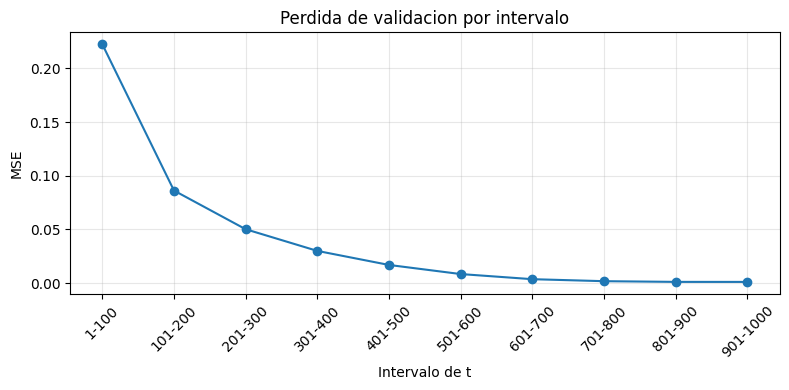

In [4]:
model.eval()
interval_losses = []

with torch.no_grad():
    for interval in range(10):
        squared_error = 0.0
        value_count = 0
        t_start = interval * 100 + 1
        t_end = (interval + 1) * 100 + 1

        for i in range(0, len(x_val), batch_size):
            x0 = x_val[i:i + batch_size]
            labels = y_val[i:i + batch_size]
            t = torch.randint(t_start, t_end, (len(x0),), device=device)
            eps = torch.randn_like(x0)
            xt = q_sample(x0, t, eps)
            predicted_eps = model(xt, t, labels)
            squared_error += torch.sum((eps - predicted_eps) ** 2).item()
            value_count += eps.numel()

        interval_loss = squared_error / value_count
        assert math.isfinite(interval_loss)
        interval_losses.append(interval_loss)
        print(f"t={t_start:04d}-{t_end - 1:04d}: perdida = {interval_loss:.5f}")

assert len(interval_losses) == 10
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), interval_losses, marker="o")
plt.xticks(range(1, 11), [f"{i * 100 + 1}-{(i + 1) * 100}" for i in range(10)], rotation=45)
plt.xlabel("Intervalo de t")
plt.ylabel("MSE")
plt.title("Perdida de validacion por intervalo")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 3.3

Se aplica el muestreo ancestral y se generan 10 imágenes por clase.

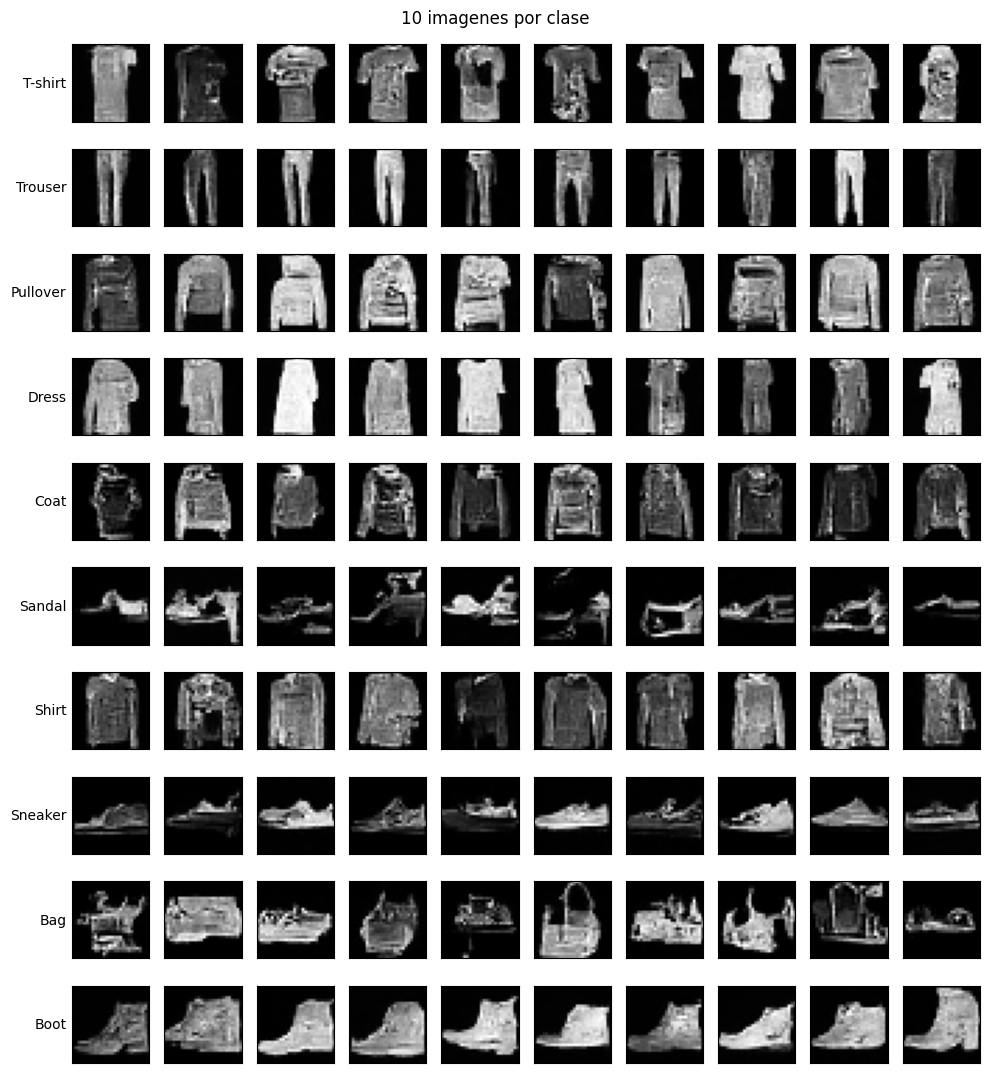

In [5]:
@torch.no_grad()
def ancestral_sample(model, labels):
    model.eval()
    x = torch.randn(len(labels), 1, 28, 28, device=device)

    for step in range(T, 0, -1):
        t = torch.full((len(labels),), step, device=device, dtype=torch.long)
        predicted_eps = model(x, t, labels)
        alpha_t = alphas[step - 1]
        alpha_bar_t = alpha_bar[step - 1]
        mean = (x - (1 - alpha_t) / torch.sqrt(1 - alpha_bar_t) * predicted_eps) / torch.sqrt(alpha_t)

        if step > 1:
            x = mean + torch.sqrt(betas[step - 1]) * torch.randn_like(x)
        else:
            x = mean

    return x.clamp(-1, 1)

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]
labels = torch.arange(10, device=device).repeat_interleave(10)
torch.manual_seed(SEED)
generated = ancestral_sample(model, labels)

assert generated.shape == (100, 1, 28, 28)
assert torch.isfinite(generated).all()

fig, axs = plt.subplots(10, 10, figsize=(10, 11))
for row in range(10):
    for col in range(10):
        index = row * 10 + col
        axs[row, col].imshow(generated[index, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
        axs[row, col].set_xticks([])
        axs[row, col].set_yticks([])
    axs[row, 0].set_ylabel(class_names[row], rotation=0, ha="right", va="center")
plt.suptitle("10 imagenes por clase")
plt.tight_layout()
plt.show()

### Task 3.4

Se aplica guía sin clasificador y se comparan fidelidad, diversidad y tiempo.

In [6]:
import time
import pandas as pd

@torch.no_grad()
def guided_prediction(model, x, t, labels, w):
    null_labels = torch.full_like(labels, 10)
    eps_uncond = model(x, t, null_labels)
    eps_cond = model(x, t, labels)
    return eps_uncond + w * (eps_cond - eps_uncond)


@torch.no_grad()
def guided_ancestral_sample(model, labels, w):
    model.eval()
    x = torch.randn(len(labels), 1, 28, 28, device=device)

    for step in range(T, 0, -1):
        t = torch.full((len(labels),), step, device=device, dtype=torch.long)
        predicted_eps = guided_prediction(model, x, t, labels, w)
        alpha_t = alphas[step - 1]
        alpha_bar_t = alpha_bar[step - 1]
        mean = (x - (1 - alpha_t) / torch.sqrt(1 - alpha_bar_t) * predicted_eps) / torch.sqrt(alpha_t)

        if step > 1:
            x = mean + torch.sqrt(betas[step - 1]) * torch.randn_like(x)
        else:
            x = mean

    return x.clamp(-1, 1)

model.eval()
test_x = x_val[:2]
test_t = torch.tensor([100, 700], device=device)
test_labels = y_val[:2]
with torch.no_grad():
    conditional = model(test_x, test_t, test_labels)
    guided_w1 = guided_prediction(model, test_x, test_t, test_labels, 1)
assert torch.allclose(guided_w1, conditional, atol=1e-6)
print("w=1 coincide con la prediccion condicional")

w=1 coincide con la prediccion condicional


In [7]:
def synchronize_device():
    if device == "cuda":
        torch.cuda.synchronize()

generated_labels = torch.arange(10, device=device).repeat_interleave(50)
guided_samples = {}
generation_times = {}

for w in [1, 3, 7]:
    sample_checkpoint = Path(f"data/task3_guided_w{w}.pt")
    if sample_checkpoint.exists():
        saved = torch.load(sample_checkpoint, map_location=device)
        guided_samples[w] = saved["samples"]
        generation_times[w] = saved["time"]
        print(f"w={w}: muestras cargadas")
        continue

    torch.manual_seed(SEED)
    synchronize_device()
    start = time.perf_counter()
    samples = guided_ancestral_sample(model, generated_labels, w)
    synchronize_device()
    elapsed = time.perf_counter() - start

    guided_samples[w] = samples
    generation_times[w] = elapsed
    torch.save({"samples": samples.cpu(), "time": elapsed}, sample_checkpoint)
    print(f"w={w}: {elapsed:.2f} segundos para 500 imagenes")

for w in guided_samples:
    guided_samples[w] = guided_samples[w].to(device)
    assert guided_samples[w].shape == (500, 1, 28, 28)
    assert torch.isfinite(guided_samples[w]).all()

w=1: 99.68 segundos para 500 imagenes
w=3: 99.52 segundos para 500 imagenes
w=7: 99.41 segundos para 500 imagenes


In [8]:
class FashionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=2, padding=1), nn.ReLU(),
        )
        self.head = nn.Sequential(
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.features(x).flatten(1))


@torch.no_grad()
def classifier_accuracy(classifier, images, labels, batch_size=256):
    classifier.eval()
    correct = 0
    for i in range(0, len(images), batch_size):
        prediction = classifier(images[i:i + batch_size]).argmax(1)
        correct += (prediction == labels[i:i + batch_size]).sum().item()
    return correct / len(images)

classifier = FashionClassifier().to(device)
classifier_optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
classifier_checkpoint = Path("data/task3_classifier_checkpoint.pt")
classifier_history = []

if classifier_checkpoint.exists():
    saved = torch.load(classifier_checkpoint, map_location=device)
    classifier.load_state_dict(saved["model"])
    classifier_optimizer.load_state_dict(saved["optimizer"])
    classifier_history = saved["history"]
    print(f"Clasificador cargado: exactitud = {classifier_history[-1]:.4f}")

classifier_batch_size = 256
for epoch in range(len(classifier_history), 20):
    classifier.train()
    permutation = torch.randperm(len(x_train), device=device)
    for i in range(0, len(x_train), classifier_batch_size):
        indices = permutation[i:i + classifier_batch_size]
        logits = classifier(x_train[indices])
        loss = nn.functional.cross_entropy(logits, y_train[indices])
        classifier_optimizer.zero_grad()
        loss.backward()
        classifier_optimizer.step()

    val_accuracy = classifier_accuracy(classifier, x_val, y_val)
    classifier_history.append(val_accuracy)
    torch.save({
        "model": classifier.state_dict(),
        "optimizer": classifier_optimizer.state_dict(),
        "history": classifier_history,
    }, classifier_checkpoint)
    print(f"Epoca {epoch + 1:02d}: exactitud = {val_accuracy:.4f}")
    if val_accuracy >= 0.88:
        break

val_accuracy = classifier_accuracy(classifier, x_val, y_val)
assert val_accuracy >= 0.88
print(f"Exactitud final: {val_accuracy:.4f}")

Epoca 01: exactitud = 0.8494
Epoca 02: exactitud = 0.8870
Exactitud final: 0.8870


In [9]:
@torch.no_grad()
def fidelity(classifier, images, requested_labels):
    predicted = []
    for i in range(0, len(images), 256):
        predicted.append(classifier(images[i:i + 256]).argmax(1))
    predicted = torch.cat(predicted)
    return (predicted == requested_labels).float().mean().item()


def diversity(images, labels):
    per_class = []
    for class_id in range(10):
        flat = images[labels == class_id].flatten(1)
        per_class.append(torch.pdist(flat, p=2).mean())
    return torch.stack(per_class).mean().item()

real_images = torch.cat([x_val[y_val == class_id][:50] for class_id in range(10)])
real_labels = torch.arange(10, device=device).repeat_interleave(50)
real_diversity = diversity(real_images, real_labels)

rows = []
for w in [1, 3, 7]:
    rows.append({
        "w": w,
        "Fidelidad global": fidelity(classifier, guided_samples[w], generated_labels),
        "Diversidad global": diversity(guided_samples[w], generated_labels),
        "Tiempo por 100 imagenes (s)": generation_times[w] / 5,
    })

results = pd.DataFrame(rows)
values = torch.tensor(results.iloc[:, 1:].values, dtype=torch.float32)
assert torch.isfinite(values).all()
print(f"Diversidad real: {real_diversity:.4f}")
display(results.round(4))

Diversidad real: 17.6752


,w,Fidelidad global,Diversidad global,Tiempo por 100 imagenes (s)
0,1,0.664,15.0974,19.9366
1,3,0.922,15.2520,19.9034
2,7,0.826,16.4734,19.8814


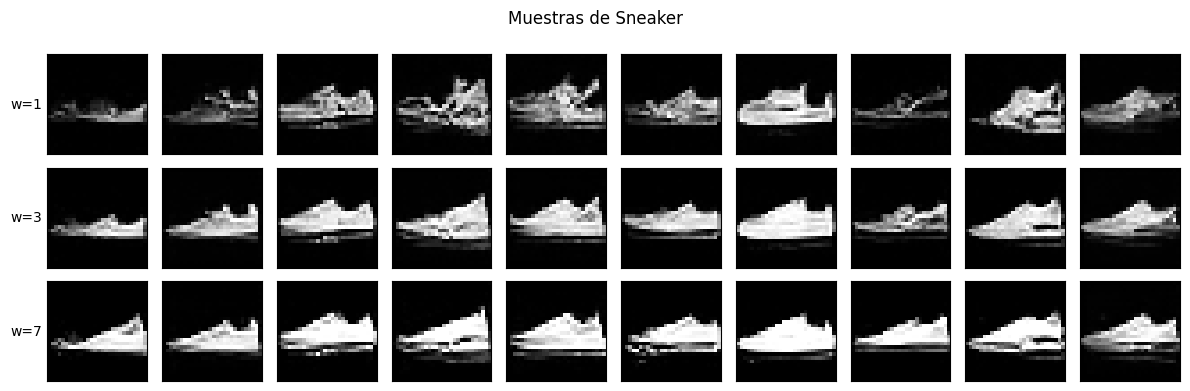

In [10]:
chosen_class = 7
fig, axs = plt.subplots(3, 10, figsize=(12, 4))
for row, w in enumerate([1, 3, 7]):
    samples = guided_samples[w][generated_labels == chosen_class][:10]
    for col in range(10):
        axs[row, col].imshow(samples[col, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
        axs[row, col].set_xticks([])
        axs[row, col].set_yticks([])
    axs[row, 0].set_ylabel(f"w={w}", rotation=0, ha="right", va="center")
plt.suptitle(f"Muestras de {class_names[chosen_class]}")
plt.tight_layout()
plt.show()

### Task 3.5

,Clase,Diversidad w=1,Diversidad w=3,Diversidad w=7,Cambio w=7 menos w=1,Fidelidad w=1,Fidelidad w=3,Fidelidad w=7
0,T-shirt,13.8811,12.3346,13.1462,-0.7349,0.72,1.00,1.00
1,Trouser,12.3042,11.2024,14.4948,2.1906,0.80,1.00,1.00
2,Pullover,17.1913,12.6274,11.4799,-5.7114,0.70,0.94,0.06
3,Dress,15.8800,15.8188,17.4017,1.5218,0.50,0.72,0.66
4,Coat,14.1175,14.2028,15.9905,1.8730,0.36,0.92,0.98
5,Sandal,15.5397,20.1467,23.7809,8.2413,0.80,0.90,1.00
6,Shirt,14.1934,15.0311,20.4786,6.2852,0.56,0.94,0.96
7,Sneaker,12.7369,12.8642,13.4111,0.6742,0.70,0.98,0.98
8,Bag,18.6678,23.0700,21.6382,2.9704,0.68,0.82,0.62
9,Boot,16.4619,15.2224,12.9119,-3.5500,0.82,1.00,1.00


Mayor caida de diversidad: Pullover (5.7114)


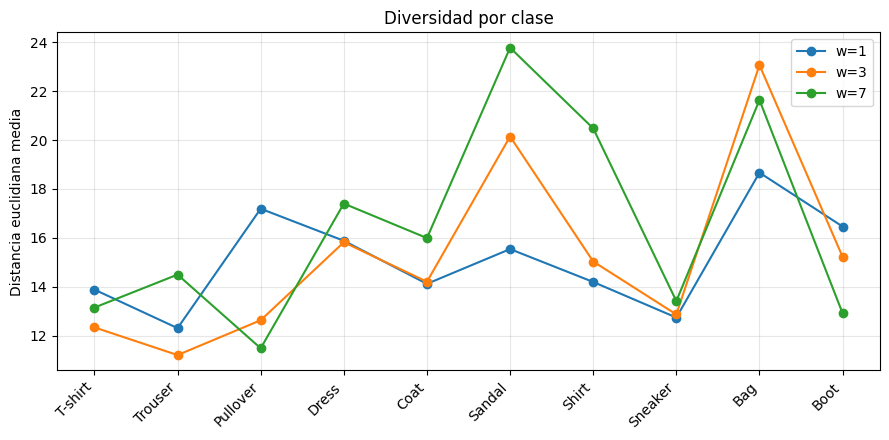

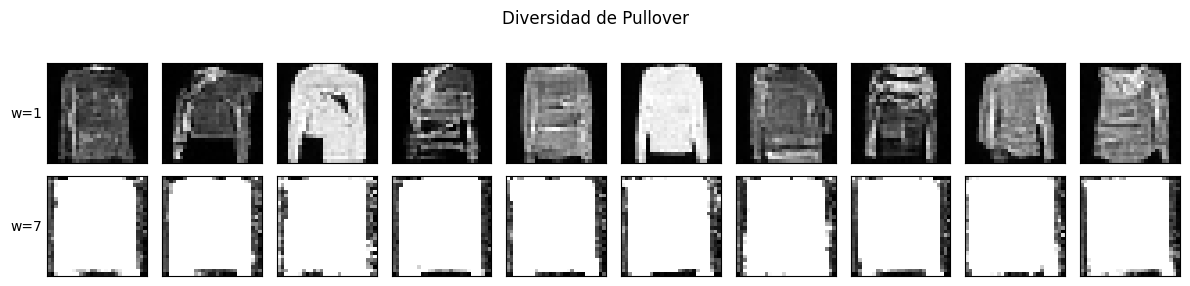

Par mas confundido: Pullover y Coat
Generadas: Pullover -> Coat = 8/50, Coat -> Pullover = 19/50
Reales: Pullover -> Coat = 41/490, Coat -> Pullover = 49/527


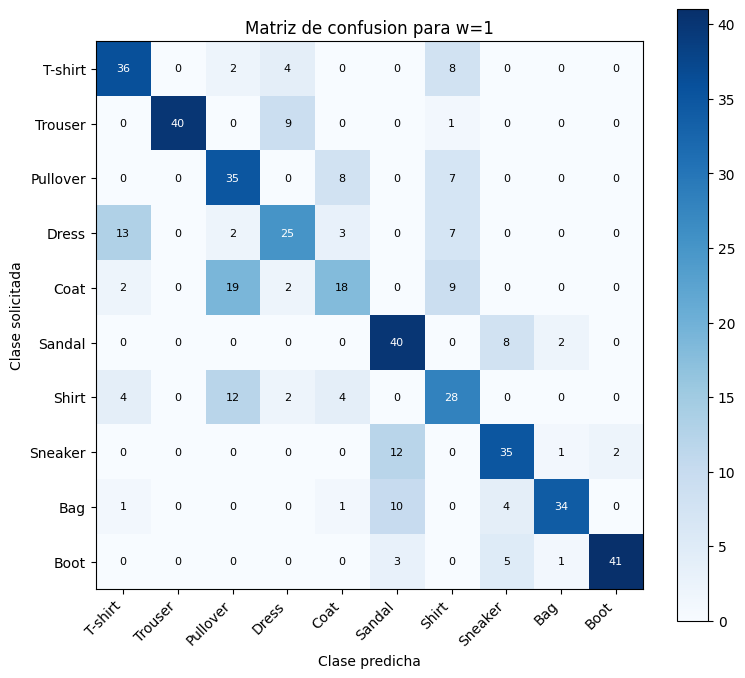

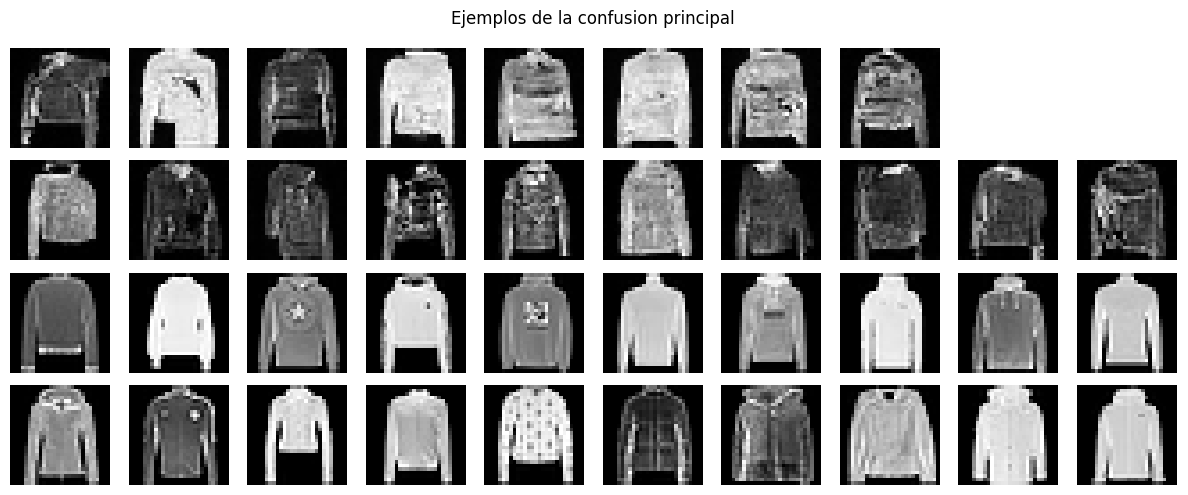

Mayor perdida: t=1-100, MSE=0.22244
Menor perdida: t=901-1000, MSE=0.00110


In [11]:

@torch.no_grad()
def predict_in_batches(classifier, images, batch_size=256):
    classifier.eval()
    predictions = []
    for i in range(0, len(images), batch_size):
        predictions.append(classifier(images[i:i + batch_size]).argmax(1))
    return torch.cat(predictions)


def confusion_matrix_tensor(true_labels, predicted_labels):
    indices = true_labels * 10 + predicted_labels
    return torch.bincount(indices, minlength=100).reshape(10, 10)


def diversity_by_class(images, labels):
    values = []
    for class_id in range(10):
        flat = images[labels == class_id].flatten(1)
        values.append(torch.pdist(flat, p=2).mean())
    return torch.stack(values)


@torch.no_grad()
def fidelity_by_class(classifier, images, labels):
    predicted = predict_in_batches(classifier, images)
    values = []
    for class_id in range(10):
        mask = labels == class_id
        values.append((predicted[mask] == class_id).float().mean())
    return torch.stack(values), predicted


# Diversidad y fidelidad por clase
diversities = {}
fidelities = {}
predictions = {}
for w in [1, 3, 7]:
    diversities[w] = diversity_by_class(guided_samples[w], generated_labels)
    fidelities[w], predictions[w] = fidelity_by_class(
        classifier, guided_samples[w], generated_labels
    )

change_1_to_7 = diversities[7] - diversities[1]
largest_drop = torch.argmax(diversities[1] - diversities[7]).item()

class_rows = []
for class_id, class_name in enumerate(class_names):
    class_rows.append({
        "Clase": class_name,
        "Diversidad w=1": diversities[1][class_id].item(),
        "Diversidad w=3": diversities[3][class_id].item(),
        "Diversidad w=7": diversities[7][class_id].item(),
        "Cambio w=7 menos w=1": change_1_to_7[class_id].item(),
        "Fidelidad w=1": fidelities[1][class_id].item(),
        "Fidelidad w=3": fidelities[3][class_id].item(),
        "Fidelidad w=7": fidelities[7][class_id].item(),
    })

class_results = pd.DataFrame(class_rows)
display(class_results.round(4))

drop_value = (diversities[1][largest_drop] - diversities[7][largest_drop]).item()
if drop_value > 0:
    print(
        f"Mayor caida de diversidad: {class_names[largest_drop]} "
        f"({drop_value:.4f})"
    )
else:
    print(
        "Ninguna clase redujo su diversidad. "
        f"El menor aumento fue {class_names[largest_drop]} ({-drop_value:.4f})."
    )

fig, ax = plt.subplots(figsize=(9, 4.5))
positions = torch.arange(10).cpu()
for w in [1, 3, 7]:
    ax.plot(positions, diversities[w].cpu(), marker="o", label=f"w={w}")
ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_ylabel("Distancia euclidiana media")
ax.set_title("Diversidad por clase")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Comparacion visual de la clase con mayor caida
affected_indices = (generated_labels == largest_drop).nonzero(as_tuple=True)[0][:10]
fig, axs = plt.subplots(2, 10, figsize=(12, 3))
for row, w in enumerate([1, 7]):
    samples = guided_samples[w][affected_indices]
    for col in range(10):
        axs[row, col].imshow(samples[col, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
        axs[row, col].set_xticks([])
        axs[row, col].set_yticks([])
    axs[row, 0].set_ylabel(f"w={w}", rotation=0, ha="right", va="center")
plt.suptitle(f"Diversidad de {class_names[largest_drop]}")
plt.tight_layout()
plt.show()

# Matriz de confusion para w=1
generated_confusion = confusion_matrix_tensor(
    generated_labels, predictions[1]
)
assert generated_confusion.sum().item() == 500

pair_scores = generated_confusion + generated_confusion.T
pair_scores.fill_diagonal_(-1)
pair_index = pair_scores.argmax().item()
class_a, class_b = divmod(pair_index, 10)

real_predictions = predict_in_batches(classifier, x_val)
real_confusion = confusion_matrix_tensor(y_val, real_predictions)

print(
    f"Par mas confundido: {class_names[class_a]} y {class_names[class_b]}"
)
print(
    f"Generadas: {class_names[class_a]} -> {class_names[class_b]} = "
    f"{generated_confusion[class_a, class_b].item()}/"
    f"{generated_confusion[class_a].sum().item()}, "
    f"{class_names[class_b]} -> {class_names[class_a]} = "
    f"{generated_confusion[class_b, class_a].item()}/"
    f"{generated_confusion[class_b].sum().item()}"
)
print(
    f"Reales: {class_names[class_a]} -> {class_names[class_b]} = "
    f"{real_confusion[class_a, class_b].item()}/"
    f"{real_confusion[class_a].sum().item()}, "
    f"{class_names[class_b]} -> {class_names[class_a]} = "
    f"{real_confusion[class_b, class_a].item()}/"
    f"{real_confusion[class_b].sum().item()}"
)

fig, ax = plt.subplots(figsize=(8, 7))
matrix_cpu = generated_confusion.cpu()
image = ax.imshow(matrix_cpu, cmap="Blues")
for row in range(10):
    for col in range(10):
        value = matrix_cpu[row, col].item()
        color = "white" if value > matrix_cpu.max().item() / 2 else "black"
        ax.text(col, row, value, ha="center", va="center", color=color, fontsize=8)
ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_yticks(range(10), class_names)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase solicitada")
ax.set_title("Matriz de confusion para w=1")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

# Ejemplos del par confundido en datos generados y reales
example_groups = [
    (
        guided_samples[1][
            (generated_labels == class_a) & (predictions[1] == class_b)
        ],
        f"Gen. {class_names[class_a]} a {class_names[class_b]}",
    ),
    (
        guided_samples[1][
            (generated_labels == class_b) & (predictions[1] == class_a)
        ],
        f"Gen. {class_names[class_b]} a {class_names[class_a]}",
    ),
    (
        x_val[(y_val == class_a) & (real_predictions == class_b)],
        f"Real {class_names[class_a]} a {class_names[class_b]}",
    ),
    (
        x_val[(y_val == class_b) & (real_predictions == class_a)],
        f"Real {class_names[class_b]} a {class_names[class_a]}",
    ),
]

fig, axs = plt.subplots(4, 10, figsize=(12, 5))
for row, (images, label) in enumerate(example_groups):
    for col in range(10):
        axs[row, col].axis("off")
        if col < len(images):
            axs[row, col].imshow(images[col, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    axs[row, 0].set_ylabel(label, rotation=0, ha="right", va="center")
plt.suptitle("Ejemplos de la confusion principal")
plt.tight_layout()
plt.show()

# Extremos de la perdida por intervalo de t
largest_interval = int(torch.tensor(interval_losses).argmax())
smallest_interval = int(torch.tensor(interval_losses).argmin())
print(
    f"Mayor perdida: t={largest_interval * 100 + 1}-{(largest_interval + 1) * 100}, "
    f"MSE={interval_losses[largest_interval]:.5f}"
)
print(
    f"Menor perdida: t={smallest_interval * 100 + 1}-{(smallest_interval + 1) * 100}, "
    f"MSE={interval_losses[smallest_interval]:.5f}"
)
